# 03 – Validation against the Keio collection

**Research question.** How well do the FBA essentiality calls of notebook 02 agree with experimental gene essentiality, once prediction and experiment refer to the same growth medium?

**Biological motivation.** The Keio collection (Baba et al. 2006) is a library of in-frame single-gene deletion mutants of *E. coli* K-12 BW25113. A gene for which no deletion mutant could be obtained is a candidate essential gene, and the growth of every mutant that does exist was measured in rich and in minimal medium. This gives an independent, genome-wide test of the model.

**Why the medium matters.** In the Keio collection a gene is an essential-gene candidate when no deletion mutant could be isolated on **LB agar**, a rich medium. A gene needed only to make an amino acid is therefore *not* essential in Keio, because LB supplies the amino acid. The model default is glucose **minimal** medium, where the same gene *is* essential. Comparing the two directly would count such genes as model errors although both answers are right.

The same paper also measured how every mutant grows in glucose MOPS minimal medium, which gives a second, minimal-medium label. So there are three comparisons:

| | Simulated medium | Experimental label | Purpose |
|---|---|---|---|
| **A** | glucose minimal | essential on LB | deliberately mismatched, to show the size of the effect |
| **B** | LB-like | essential on LB | matched, rich medium |
| **C** | glucose minimal | essential on LB or no growth in glucose MOPS | matched, minimal medium |

**What this notebook does.**
- turns the Keio tables into experimental essentiality labels and checks the parser against the numbers stated in the paper
- scores the predictions against the labels in the three comparisons (confusion matrix, precision, recall, MCC)
- checks how robust comparison C is to the no-growth cut-off and to the strain background (MG1655 model, BW25113 mutants)

**Expected outputs.**
- `results/tables/metrics.csv`, `comparison_glucose.csv`, `comparison_lb.csv`, `mops_cutoff_sensitivity.csv`
- `results/figures/keio_growth_lb_vs_mops.png`, `validation_metrics.png`
- headline numbers: 1,508 scored genes; MCC 0.54 (A), 0.72 (B) and 0.76 (C)

Before running this notebook, download the Keio tables once with `python scripts/fetch_keio.py` (see `data/README.md`) and run notebook 02, whose knockout tables are read here. Runtime: about one minute.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ecoli_fba import RESULTS_DIR, evaluate, keio, knockout, media, plotting
from ecoli_fba.model import load_model

plotting.apply_style()
TABLES_DIR = RESULTS_DIR / "tables"

missing = [name for name in keio.RAW_FILES if not (keio.RAW_DIR / name).is_file()]
assert not missing, f"Run `python scripts/fetch_keio.py` first; missing: {missing}"

## 1. The Keio tables
Supplementary Table 3 of Baba et al. (2006) has one row per targeted ORF: how many of the tested colonies carried the correct deletion, and the OD600 of the mutant in LB and in glucose MOPS medium. The paper scores a mutant as obtained "if two or more colonies had the expected structure".

First check that the parsed table reproduces the numbers stated in the paper.

OD600 is the optical density (turbidity) of a culture at 600 nm, the standard proxy for cell density: a culture that does not grow stays at a low OD600.

In [2]:
baba = keio.read_baba_table_s3()
no_mutant = baba["targeted"] & ~baba["mutant_obtained"]

pd.DataFrame(
    {
        "this table": [int(baba["targeted"].sum()), int(baba["mutant_obtained"].sum()), int(no_mutant.sum())],
        "Baba et al. 2006": [4288, 3985, 303],
    },
    index=["ORFs targeted", "deletion mutants obtained", "no mutant (essential gene candidates)"],
)

,this table,Baba et al. 2006
ORFs targeted,4288,4288
deletion mutants obtained,3985,3985
no mutant (essential gene candidates),303,303


In [3]:
# The same 303 candidates as the paper's own list (Supplementary Table 6)?
set(baba.loc[no_mutant, "jw_id"]) == set(keio.read_baba_table_s6()["jw_id"])

True

### From ORFs to genes
The model identifies genes by MG1655 b-number. `keio.build_labels` keeps the ORFs that have a b-number and merges the few genes that were targeted as two separate ORFs.

Yamamoto et al. (2009) later re-examined the collection and found mutants in which **both** isolates still carry an intact copy of the "deleted" gene (a partial duplication). For those genes the existence of a mutant does not show that the gene is dispensable. They are flagged in `duplication_2009` but their labels are **not** changed here.

In [4]:
labels = keio.build_labels(baba, keio.read_yamamoto_table_s5())

pd.Series(
    {
        "genes with a b-number": len(labels),
        "never targeted (no label)": int((~labels["targeted"]).sum()),
        "essential on LB (no mutant)": int(labels["lb_essential"].sum()),
        "mutant exists, no growth in glucose MOPS": int((labels["glucose_essential"] & ~labels["lb_essential"]).sum()),
        "essential on glucose minimal (sum of the two)": int(labels["glucose_essential"].sum()),
        "mutant flagged as duplication in 2009": int(labels["duplication_2009"].sum()),
    },
    name="number of genes",
)

genes with a b-number                            4281
never targeted (no label)                          73
essential on LB (no mutant)                       299
mutant exists, no growth in glucose MOPS          103
essential on glucose minimal (sum of the two)     402
mutant flagged as duplication in 2009              25
Name: number of genes, dtype: int64

## 2. Growth of the mutants in rich and minimal medium
Each point is one deletion mutant. Mutants in the lower band grow in LB but not in glucose MOPS medium: they need something that only the rich medium provides.

"No growth" is defined as OD600 below **0.08** after 48 h. This is the cut-off the paper itself uses in its Table III (mean minus two standard deviations of all mutants).

How to read it: points to the right but below the line are mutants that grow well in LB but not in minimal medium, i.e. conditionally essential (auxotrophic) genes. These genes are what separates comparison A from comparison C.

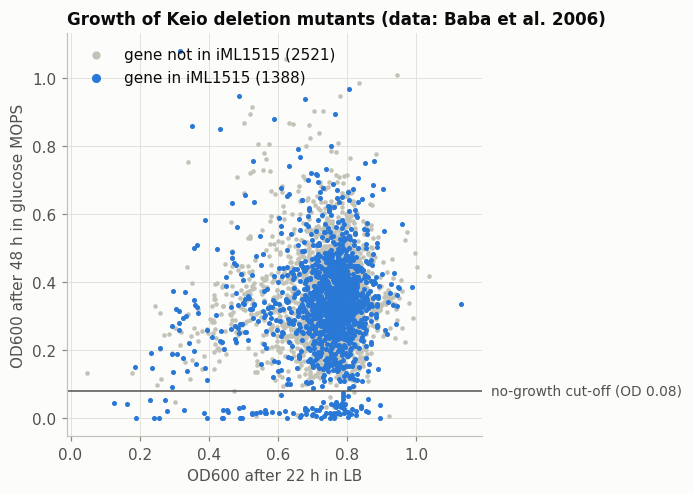

In [5]:
model = load_model()
model_genes = {g.id for g in model.genes}

mutants = labels[labels["mutant_obtained"] & labels["od_mops_48h"].notna()]
in_model = mutants["gene_id"].isin(model_genes)

fig, ax = plt.subplots(figsize=(6.4, 4.6))
ax.scatter(mutants.loc[~in_model, "od_lb_22h"], mutants.loc[~in_model, "od_mops_48h"],
           s=9, color=plotting.NEUTRAL, linewidths=0, label=f"gene not in iML1515 ({(~in_model).sum()})")
ax.scatter(mutants.loc[in_model, "od_lb_22h"], mutants.loc[in_model, "od_mops_48h"],
           s=11, color=plotting.BLUE, linewidths=0, label=f"gene in iML1515 ({in_model.sum()})")
ax.axhline(keio.MOPS_NO_GROWTH_OD, color=plotting.INK_SECONDARY, linewidth=1)
ax.annotate("no-growth cut-off (OD 0.08)", xy=(1.19, keio.MOPS_NO_GROWTH_OD), xytext=(6, 0),
            textcoords="offset points", ha="left", va="center", fontsize=9,
            color=plotting.INK_SECONDARY, annotation_clip=False)
ax.set_xlim(-0.01, 1.19)
ax.set_xlabel("OD600 after 22 h in LB")
ax.set_ylabel("OD600 after 48 h in glucose MOPS")
ax.set_title("Growth of Keio deletion mutants (data: Baba et al. 2006)")
ax.legend(loc="upper left", markerscale=1.8)
fig.tight_layout()
plotting.save_figure(fig, "keio_growth_lb_vs_mops")
plt.show()

## 3. Model genes that have a label

iML1515 identifies genes by their MG1655 b-number, the identifier the Keio table also uses, so labels are matched by b-number.

In [6]:
model_labels = labels[labels["gene_id"].isin(model_genes)]
unlabelled = model_labels[~model_labels["targeted"]]

print("Model genes found in the Keio table:", len(model_labels), "of", len(model_genes) - 1)
print("Without a label (never targeted):  ", sorted(unlabelled["gene_name"]))

pd.DataFrame(
    {
        "essential on LB": model_labels["lb_essential"].value_counts(dropna=False),
        "essential on glucose minimal": model_labels["glucose_essential"].value_counts(dropna=False),
    }
).rename(index={True: "essential", False: "not essential", pd.NA: "no label"})

Model genes found in the Keio table: 1515 of 1515
Without a label (never targeted):   ['araA', 'araB', 'araD', 'lacZ', 'rhaA', 'rhaB', 'rhaD']


,essential on LB,essential on glucose minimal
not essential,1388,1295
essential,120,213
no label,7,7


The seven unlabelled genes are deleted or disrupted in BW25113 itself, the parent strain of the Keio collection, so no knockout of them exists. They are left out of every comparison.

## 4. The three comparisons
The positive class is "essential":

- **TP** predicted essential, observed essential
- **FP** predicted essential, observed non-essential
- **FN** predicted non-essential, observed essential
- **TN** predicted non-essential, observed non-essential

Essential genes are a minority, so accuracy alone is misleading: a model that calls every gene non-essential would already be 86 to 92 % accurate on these data. Precision, recall and the Matthews correlation coefficient (MCC) are reported as well.

- **precision** = TP / (TP + FP): of the genes the model calls essential, the fraction that is essential in the experiment
- **recall** = TP / (TP + FN): of the experimentally essential genes, the fraction the model finds
- **MCC** uses all four cells, ranges from −1 to 1 (0 = no better than chance) and stays informative when one class is rare

In [7]:
predictions = {
    "glucose_minimal": pd.read_csv(TABLES_DIR / "knockout_glucose_minimal.csv"),
    "lb_like": pd.read_csv(TABLES_DIR / "knockout_lb_like.csv"),
}
COMPARISONS = {
    "A: glucose minimal vs LB labels (mismatched)": ("glucose_minimal", "lb_essential"),
    "B: LB-like vs LB labels": ("lb_like", "lb_essential"),
    "C: glucose minimal vs glucose labels": ("glucose_minimal", "glucose_essential"),
}

merged = {}
for name, (medium, label_column) in COMPARISONS.items():
    observed = labels.rename(columns={label_column: "observed_essential"})
    merged[name] = evaluate.compare(predictions[medium], observed)

metrics = pd.DataFrame(
    {name: evaluate.metrics(evaluate.confusion_counts(table["outcome"])) for name, table in merged.items()}
).T
metrics.index.name = "comparison"
metrics.round(4).to_csv(TABLES_DIR / "metrics.csv")

count_columns = ["n_genes", "n_observed_essential", "n_predicted_essential", "TP", "FP", "FN", "TN"]
metrics[count_columns].astype(int)

,n_genes,n_observed_essential,n_predicted_essential,TP,FP,FN,TN
comparison,,,,,,,
A: glucose minimal vs LB labels (mismatched),1508,120,195,89,106,31,1282
B: LB-like vs LB labels,1508,120,116,87,29,33,1359
C: glucose minimal vs glucose labels,1508,213,195,161,34,52,1261


In [8]:
metrics[["accuracy", "precision", "recall", "specificity", "balanced_accuracy", "f1", "mcc"]].round(3)

,accuracy,precision,recall,specificity,balanced_accuracy,f1,mcc
comparison,,,,,,,
A: glucose minimal vs LB labels (mismatched),0.909,0.456,0.742,0.924,0.833,0.565,0.537
B: LB-like vs LB labels,0.959,0.750,0.725,0.979,0.852,0.737,0.715
C: glucose minimal vs glucose labels,0.943,0.826,0.756,0.974,0.865,0.789,0.757


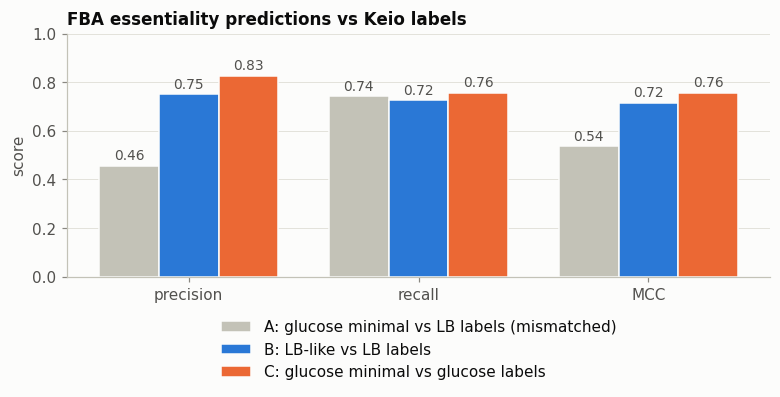

In [9]:
shown = ["precision", "recall", "mcc"]
colors = [plotting.NEUTRAL, plotting.BLUE, plotting.ORANGE]
x = np.arange(len(shown))
width = 0.26

fig, ax = plt.subplots(figsize=(7.2, 3.8))
for i, (name, color) in enumerate(zip(metrics.index, colors)):
    values = metrics.loc[name, shown].astype(float)
    bars = ax.bar(x + (i - 1) * width, values, width=width, color=color, label=name)
    ax.bar_label(bars, labels=[f"{v:.2f}" for v in values], padding=2, fontsize=9, color=plotting.INK_SECONDARY)
ax.set_xticks(x, ["precision", "recall", "MCC"])
ax.set_ylim(0, 1)
ax.set_ylabel("score")
ax.set_title("FBA essentiality predictions vs Keio labels")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=1)
fig.tight_layout()
plotting.save_figure(fig, "validation_metrics")
plt.show()

In [10]:
# Per-gene results of the two matched comparisons, used by notebook 04.
keep = ["gene_id", "gene_name", "growth_ratio", "predicted_essential", "observed_essential", "outcome"]
merged["B: LB-like vs LB labels"][keep].to_csv(TABLES_DIR / "comparison_lb.csv", index=False)
merged["C: glucose minimal vs glucose labels"][keep].to_csv(TABLES_DIR / "comparison_glucose.csv", index=False)

For orientation only: Bernstein et al. (2023) quote an overall accuracy of 93.4 % for iML1515 from the original model publication (Monk et al. 2017). That number comes from a different data set and several carbon sources, so it is not directly comparable with the table above.

## 5. Robustness checks
### 5.1 The no-growth cut-off
Comparison C depends on where "no growth in glucose MOPS" is drawn. The table repeats it for other cut-offs and for the 24 h reading.

In [11]:
rows = []
for timepoint in ["od_mops_24h", "od_mops_48h"]:
    for cutoff in [0.04, 0.06, 0.08, 0.10, 0.15]:
        no_growth = (labels[timepoint] < cutoff).astype("boolean").where(labels[timepoint].notna())
        alternative = labels.assign(observed_essential=(labels["lb_essential"] | no_growth).where(labels["targeted"]))
        table = evaluate.compare(predictions["glucose_minimal"], alternative)
        m = evaluate.metrics(evaluate.confusion_counts(table["outcome"]))
        rows.append({"reading": timepoint, "OD cut-off": cutoff} | {k: m[k] for k in ["n_observed_essential", "TP", "FP", "FN", "precision", "recall", "mcc"]})

cutoff_sensitivity = pd.DataFrame(rows).set_index(["reading", "OD cut-off"])
cutoff_sensitivity.round(4).to_csv(TABLES_DIR / "mops_cutoff_sensitivity.csv")
cutoff_sensitivity.round(3)

n_observed_essential   TP  FP  FN  precision  recall  \
reading     OD cut-off                                                         
od_mops_24h 0.04                         215  160  35  55      0.821   0.744   
            0.06                         221  166  29  55      0.851   0.751   
            0.08                         225  168  27  57      0.862   0.747   
            0.10                         231  170  25  61      0.872   0.736   
            0.15                         242  171  24  71      0.877   0.707   
od_mops_48h 0.04                         198  153  42  45      0.785   0.773   
            0.06                         209  158  37  51      0.810   0.756   
            0.08                         213  161  34  52      0.826   0.756   
            0.10                         218  163  32  55      0.836   0.748   
            0.15                         265  170  25  95      0.872   0.642   

                          mcc  
reading     OD cut-off         
od_mops_24h 0.04        0.747  
            0.06        0.768  
            0.08        0.770  
            0.10        0.769  
            0.15        0.752  
od_mops_48h 0.04        0.745  
            0.06        0.749  
            0.08        0.757  
            0.10        0.758  
            0.15        0.705

### 5.2 The parent strain
iML1515 describes *E. coli* K-12 MG1655, but the Keio collection was built in BW25113, which lacks the seven genes listed in section 3. Does deleting them in the model first change any essentiality call?

In [12]:
background = sorted(unlabelled["gene_id"])
others = [g for g in predictions["glucose_minimal"]["gene_id"] if g not in background]

rows = []
for medium_name, medium in [
    ("glucose_minimal", media.glucose_minimal_medium(model)),
    ("lb_like", media.lb_like_medium(model, media.glucose_minimal_medium(model))[0]),
]:
    with model:
        media.apply_medium(model, medium)
        for gene_id in background:
            model.genes.get_by_id(gene_id).knock_out()
        result = knockout.run_knockouts(model, genes=others)
    in_background = set(result.loc[knockout.classify_essential(result["growth_ratio"]), "gene_id"])
    in_mg1655 = set(predictions[medium_name].query("predicted_essential")["gene_id"]) - set(background)
    rows.append({"medium": medium_name, "essential (MG1655 model)": len(in_mg1655),
                 "essential (BW25113 background)": len(in_background),
                 "calls that differ": len(in_mg1655 ^ in_background)})

pd.DataFrame(rows).set_index("medium")

,essential (MG1655 model),essential (BW25113 background),calls that differ
medium,,,
glucose_minimal,195,195,0
lb_like,116,116,0


**Questions and answers**

1. *Comparison A and comparison C use the same predictions. Which number changes most between them, and what kind of genes are responsible?*
   The number of false positives, from 106 to 34, which raises precision from 0.46 to 0.83 and MCC from 0.54 to 0.76; recall barely moves. Exactly 72 genes switch from false positive in A to true positive in C. They are biosynthetic genes, counted once per pathway: cofactors (15), purines and pyrimidines (14), aromatic amino acids (10), arginine and proline (9), histidine (8), branched-chain amino acids (6) and cysteine (4), among others. Their mutants grow in LB but not in glucose MOPS medium, so the model was right about minimal medium. False negatives rise from 31 to 52 because the glucose label adds 93 essential genes, 21 of which the model misses.

2. *Accuracy is above 90 % in all three comparisons, including the mismatched one. Why is accuracy a poor guide here, and which metric shows the difference best?*
   Only 8.0 % (LB label) and 14.1 % (glucose label) of the scored genes are essential, so calling every gene non-essential would already give an accuracy of 92.0 % and 85.9 %. The mismatched comparison A (0.909) is in fact slightly below that trivial baseline. MCC shows the difference best (0.54 in A against 0.76 in C) because it uses all four cells of the confusion matrix and cannot be inflated by a constant prediction; precision shows it too.

3. *The no-growth cut-off (section 5.1) changes the number of observed essential genes. How stable is the overall conclusion?*
   Stable. Over all cut-offs tested (OD600 0.04 to 0.15, at 24 h or 48 h) the number of observed essential genes ranges from 198 to 265 and the MCC from 0.705 to 0.770; between 0.06 and 0.10 it stays between 0.749 and 0.770. Stricter cut-offs trade recall for precision and vice versa. The lowest value, 0.705 at 0.15 and 48 h, comes from counting many slow growers as essential (recall falls to 0.64). Even then, comparison C stays far above the mismatched comparison A (0.54).

4. *A gene is "essential on LB" when no mutant could be isolated. Can you think of reasons other than essentiality why a deletion mutant might not be obtained?*
   Baba et al. (2006) discuss several:
   - **Conditional essentiality on the selection medium.** LB lacks diaminopimelic acid, so *dapA*, *dapB* and *dapE* mutants could not be recovered, and mutants in some central metabolic genes such as *gapA* fail on the media used, possibly because toxic intermediates accumulate.
   - **Technical failures.** Unrecognised IS elements at the target site prevented recombination, and in rare cases a deletion failed with one primer batch and worked with another.
   - **Polar effects** on neighbouring genes in an operon. The Keio deletions were designed in frame to minimise them, and an earlier essentiality call for *hlpA* was attributed to a polar effect on *lpxD*.
   - The scoring rule itself: a mutant counts as obtained only if at least two of the tested colonies carry the correct deletion.

5. *What does the `duplication_2009` flag imply for genes that the model calls essential but Keio lists as deletable?*
   The "deletion mutant" still carries an intact copy of the gene, so its viability does not show that the gene is dispensable. Six false positives of comparison C carry the flag (*coaA*, *coaE*, *folP*, *glmM*, *hemE*, *lptB*); for them the model may well be right. Counting them as essential would give 167 TP and 28 FP in comparison C, i.e. precision 0.856, recall 0.763 and MCC 0.778 instead of 0.757. The labels were deliberately not changed in the analysis, so that no label is adjusted after looking at the errors; the calculation only shows the size of the effect.

## Notes

**Observations**
- The parsed table reproduces the numbers stated in the paper exactly (4,288 targeted ORFs, 3,985 mutants, 303 essential-gene candidates), and the 0.08 cut-off equals the mean minus two standard deviations of all mutants.
- Recall is almost the same in all three comparisons (0.725 to 0.756). The false negatives do not depend on which label is used; they are a property of the model.
- The strain difference between MG1655 and BW25113 (seven genes) changes no essentiality call.

**To check next**
- Inspect each false positive and false negative, including the borderline mutants whose OD600 lies close to the 0.08 cut-off.

Next notebook: look at the false positives and false negatives one by one.